# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [6]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [8]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [9]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [10]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.

In [12]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [13]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [14]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [15]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [16]:

# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean())

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [17]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("\nProporción de valores nulos:")
print(usage.isna().mean())

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
- Hint:
- Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
- Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
- Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 

---

### Diagnóstico de Valores Nulos:
- **`users['churn_date']`**: Presenta 88.35% de nulos[cite: 2]; se mantienen como nulos porque indican usuarios activos que no han cancelado el servicio.
- **`users['city']`**: Presenta 11.73% de nulos[cite: 2]; al estar entre 5% y 30% se deben investigar e imputar (ej. como "Desconocido" o `pd.NA`) para no descartar al usuario.
- **`usage['date']`**: Presenta 0.13% de nulos (50 filas)[cite: 2]; al ser menor al 5%, se pueden ignorar o eliminar puntualmente sin afectar la muestra.
- **`usage['duration']` y `usage['length']`**: Presentan 55.19% y 44.74% de nulos respectivamente[cite: 2]; se dejan como nulos porque son datos condicionales (MAR), ya que los mensajes no tienen duración y las llamadas no tienen caracteres.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [18]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [19]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [21]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"--- Valores únicos en {col} ---")
    print(users[col].value_counts(dropna=False))
    print()



--- Valores únicos en city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- Valores únicos en plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` ...
- La columna `plan` ...

In [22]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**
- ¿En qué columnas encontraste valores inválidos o sentinels?
- ¿Qué acción tomarías?

---

### Diagnóstico: Valores Inválidos o Sentinels

* **¿En qué columnas encontraste valores inválidos o sentinels?**
  - **`users['age']`**: Se detectó el valor sentinel `-999`, el cual es un código de captura erróneo que afecta los cálculos estadísticos (mínimo de -999 y distorsión de la media)[cite: 4].
  - **`users['city']`**: Se encontró el sentinel `'?'` en 96 filas, que representa registros donde no se capturó la ciudad del usuario[cite: 5].

* **¿Qué acción tomarías?**
  - **`age`**: Reemplazar el sentinel `-999` por la mediana de las edades válidas (sin considerar los valores negativos) para preservar la integridad del registro sin sesgar la distribución[cite: 4].
  - **`city`**: Reemplazar los valores `'?'` por `pd.NA` (nulos estándar) para homogeneizar todos los datos de ciudad no informados en un solo formato limpio[cite: 5].


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [24]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [25]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [26]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [27]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.


✍️ **Comentario**: escribe tu diagnóstico, e incluye qué acción recomendarías para cada caso:

**Fechas fuera de rango**
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

### Diagnóstico: Fechas Fuera de Rango

* **¿Aparecen años imposibles?**
  - **`users['reg_date']`**: Sí, aparecen 40 registros con el año **2026**[cite: 6]. Dado que el corte del dataset es el año 2024, corresponden a fechas futuras/imposibles causadas por un error de captura o tipeo en el registro[cite: 6].
  - **`usage['date']`**: No presenta años fuera de rango (todos los eventos con fecha válida son de 2024), aunque contiene 50 valores nulos[cite: 6].

* **¿Qué harías con ellas?**
  - En **`users['reg_date']`**: Marcar las fechas del año 2026 como nulas (`pd.NA`) para no sesgar el análisis de antigüedad o retención sin perder los demás datos del usuario.
  - En **`usage['date']`**: Conservar las filas o marcar como `pd.NA` los 50 registros faltantes, ya que representan una fracción mínima (0.13%) del volumen total[cite: 2, 6].

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [28]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [29]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [32]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [33]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())



type
call        0
text    22076
Name: duration, dtype: int64

In [34]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquí y escribe tu diagnóstico de nulos en `duration` y `length`

---

### Diagnóstico de Nulos: Verificación MAR (Missing At Random)

* **`duration`**: Presenta 0 nulos en llamadas (`call`) y 22,076 nulos en mensajes (`text`)[cite: 6]. Los valores faltantes dependen al 100% de la columna `type`, ya que a los mensajes de texto no les corresponde una duración de llamada[cite: 6].
* **`length`**: Presenta 0 nulos en mensajes (`text`) y 17,896 nulos en llamadas (`call`)[cite: 6]. Al igual que en el caso anterior, dependen totalmente de `type`, puesto que las llamadas de voz no cuentan con longitud de caracteres[cite: 6].
* **Decisión y justificación**: Se confirma empíricamente que son faltantes condicionales (**Missing At Random - MAR**)[cite: 6]. La acción es **dejarlos como nulos**[cite: 6], ya que imputarles valores (como ceros o promedios) sesgaría los cálculos estadísticos de consumo para cada tipo de servicio por separado.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [38]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)



,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [39]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [40]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01



### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.


In [41]:
# Resumen estadístico de las columnas numéricas
metricas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[metricas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [42]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

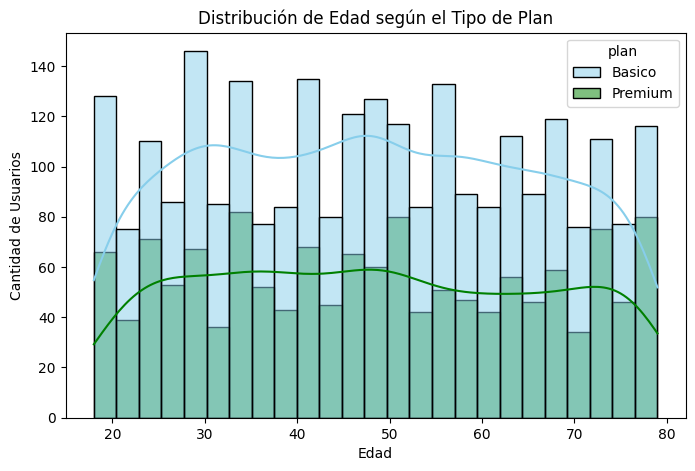

In [43]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=25
)
plt.title('Distribución de Edad según el Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡 Insights:
- Distribución: La variable `age` tiene una distribución **aproximadamente uniforme o simétrica** a lo largo de todo el rango de edades (entre los 18 y casi 80 años)[cite: 4]. No muestra un sesgo marcado hacia la derecha ni hacia la izquierda.
- Plan y edad: No existe un patrón etario diferenciador; la proporción de usuarios entre el plan **Básico** y **Premium** se mantiene constante y homogénea en todos los grupos de edad.

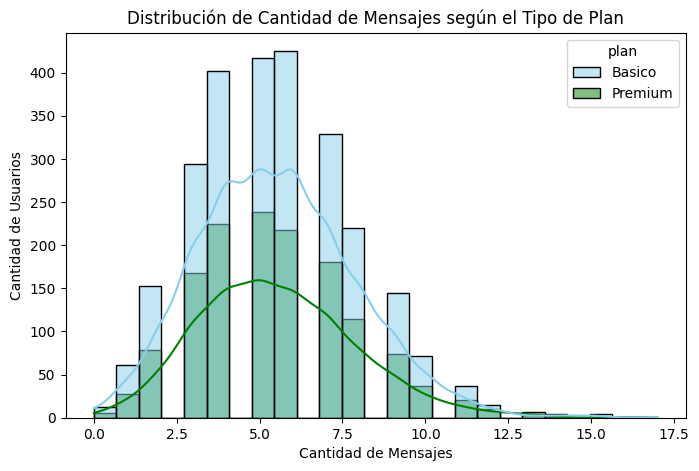

In [44]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=25
)
plt.title('Distribución de Cantidad de Mensajes según el Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡 Insights:
- Distribución: La variable `cant_mensajes` tiene una **distribución unimodal con un leve sesgo a la derecha (positivo)**, concentrando a la gran mayoría de usuarios entre 3 y 8 mensajes, con valores máximos que superan los 12 mensajes.
- Plan y mensajes: Tanto los clientes del plan **Básico** como los del plan **Premium** presentan el mismo patrón de consumo, con su punto de mayor concentración alrededor de los 5 a 6 mensajes. No se aprecia una diferencia significativa en la cantidad de mensajes enviados según el tipo de plan.

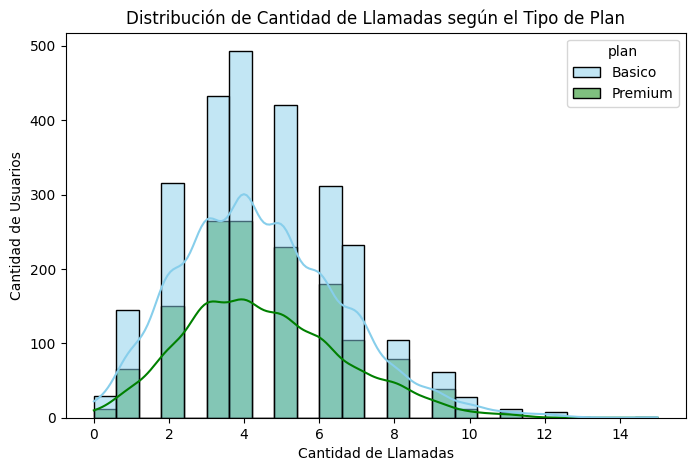

In [45]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=25
)
plt.title('Distribución de Cantidad de Llamadas según el Tipo de Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡 Insights:
- Distribución: La variable `cant_llamadas` tiene una **distribución unimodal con sesgo positivo (a la derecha)**[cite: 4]. La mayor concentración de usuarios se ubica entre 3 y 6 llamadas, decayendo gradualmente con pocos casos por encima de las 9 llamadas[cite: 4].
- Plan y llamadas: Los usuarios de ambos planes muestran un comportamiento muy similar, alcanzando su pico alrededor de las 4 llamadas tanto en **Básico** como en **Premium**[cite: 4]. No existe una diferencia clara o patrón de segmentación en la cantidad de llamadas realizadas según el tipo de plan[cite: 4].

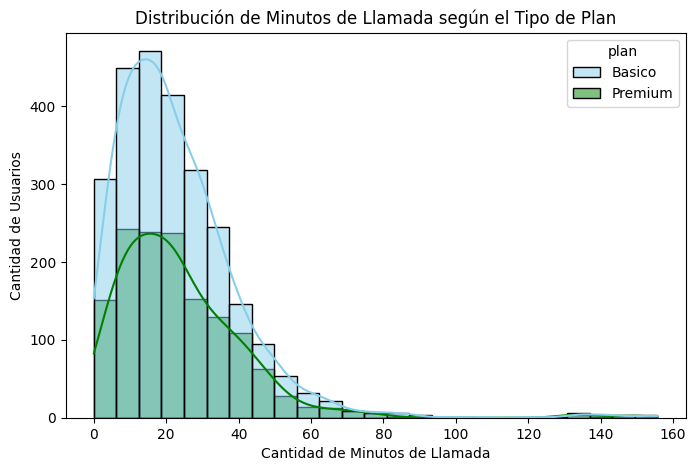

In [46]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=25
)
plt.title('Distribución de Minutos de Llamada según el Tipo de Plan')
plt.xlabel('Cantidad de Minutos de Llamada')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡 Insights:
- Distribución: La variable `cant_minutos_llamada` presenta una **distribución unimodal fuertemente sesgada a la derecha (sesgo positivo)**[cite: 5]. La gran mayoría de usuarios acumula entre 10 y 30 minutos de llamada, con una cola larga que se extiende hacia consumos elevados (incluso superando los 80 a 140 minutos)[cite: 5].
- Plan y minutos de llamada: Tanto en el plan **Básico** como en el plan **Premium**, el comportamiento de consumo es prácticamente idéntico, concentrando su pico alrededor de los 15 a 20 minutos[cite: 5]. No se observa una tendencia de mayor tiempo en llamada por parte de los clientes con plan Premium[cite: 5].

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

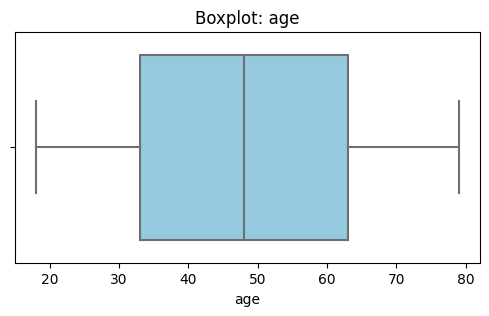

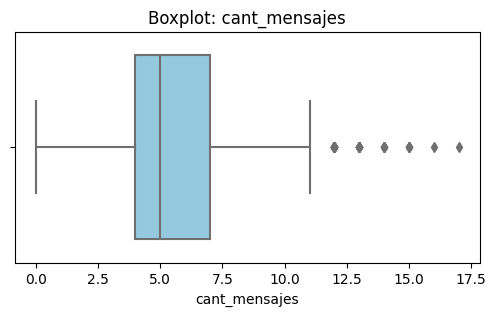

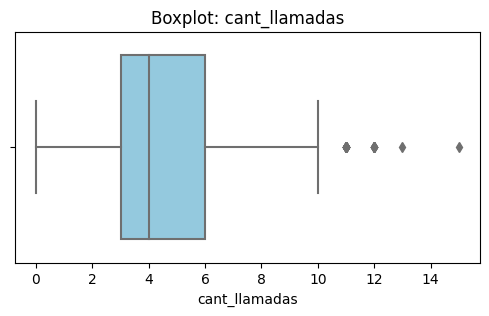

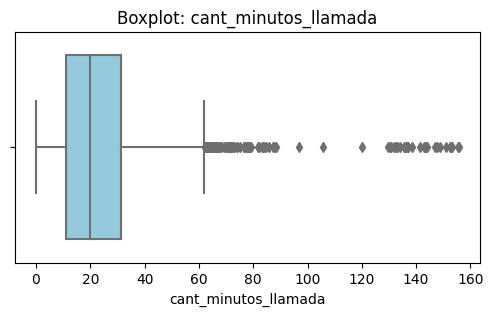

In [47]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡 Insights:
* **age**: **No presenta outliers**[cite: 6]. Los valores se distribuyen de forma continua y homogénea entre ~18 y ~79 años dentro de los bigotes del boxplot[cite: 6].
* **cant_mensajes**: **Sí presenta outliers superiores** (a la derecha)[cite: 6]. Hay observaciones aisladas a partir de aproximadamente 12 mensajes, extendiéndose hasta 17[cite: 6].
* **cant_llamadas**: **Sí presenta outliers superiores** (a la derecha)[cite: 7]. Se observan puntos aislados a partir de 11 llamadas, alcanzando un máximo de 15[cite: 7].
* **cant_minutos_llamada**: **Sí presenta una cantidad considerable de outliers superiores** (a la derecha)[cite: 7]. A partir de aproximadamente 62 minutos se detecta una larga fila de valores atípicos que llegan hasta cerca de 160 minutos[cite: 7].

In [48]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    
    limite_superior = q3 + 1.5 * iqr
    outliers = user_profile[user_profile[col] > limite_superior]
    
    print(f"Columna: {col}")
    print(f"  Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"  Límite superior: {limite_superior:.2f}")
    print(f"  Cantidad de outliers: {len(outliers)} ({len(outliers)/len(user_profile)*100:.2f}%)\n")




Columna: cant_mensajes
  Q1: 4.00 | Q3: 7.00 | IQR: 3.00
  Límite superior: 11.50
  Cantidad de outliers: 46 (1.15%)

Columna: cant_llamadas
  Q1: 3.00 | Q3: 6.00 | IQR: 3.00
  Límite superior: 10.50
  Cantidad de outliers: 30 (0.75%)

Columna: cant_minutos_llamada
  Q1: 11.12 | Q3: 31.41 | IQR: 20.30
  Límite superior: 61.86
  Cantidad de outliers: 109 (2.73%)



In [49]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000



💡 Insights:

* **cant_mensajes**: **Mantener los outliers.** Aunque el límite superior es 11.50 y el máximo llega a 17 mensajes[cite: 8], solo representan el 1.15% del total (46 usuarios)[cite: 8]. Enviar 17 mensajes es un comportamiento completamente plausible y no responde a un error de carga ni técnico.
* **cant_llamadas**: **Mantener los outliers.** El límite superior es 10.50 y el valor máximo alcanza 15 llamadas[cite: 8], representando apenas el 0.75% (30 usuarios)[cite: 8]. Realizar 15 llamadas es totalmente viable en el uso cotidiano de un cliente de telecomunicaciones.
* **cant_minutos_llamada**: **Mantener los outliers.** El límite superior es de 61.86 minutos y el máximo se sitúa en ~155.69 minutos[cite: 8], abarcando a 109 usuarios (2.73%)[cite: 8]. Una duración total acumulada de ~2.5 horas de llamadas es un consumo normal para clientes intensivos (*heavy users*); eliminarlos sesgaría el análisis del consumo real de la red.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:

# Crear columna grupo_uso



In [ ]:
# verificar cambios
user_profile.head()

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [50]:
# Crear columna grupo_uso
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

# Verificar la distribución del nuevo segmento
user_profile['grupo_uso'].value_counts()


Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

In [51]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

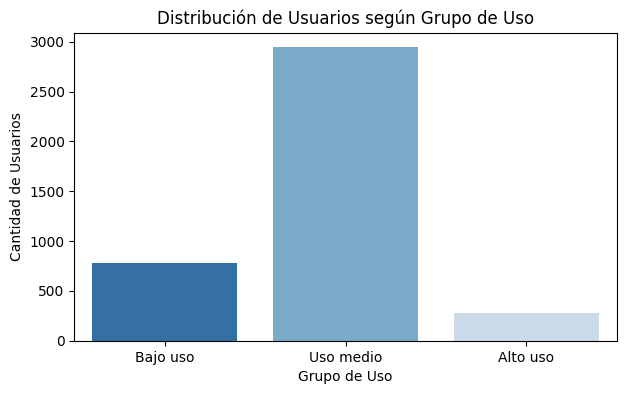

In [53]:

# Visualización de los segmentos por uso
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette='Blues_r'
)
plt.title('Distribución de Usuarios según Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()



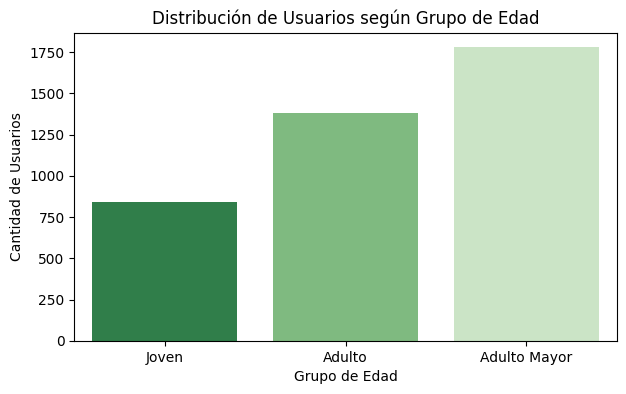

In [56]:
# Crear la columna si no se ejecutó en el paso anterior
user_profile['grupo_edad'] = pd.cut(
    user_profile['age'], 
    bins=[0, 30, 50, 100], 
    labels=['Joven', 'Adulto', 'Adulto Mayor']
)

# Visualización de los segmentos por edad
plt.figure(figsize=(7, 4))
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    palette='Greens_r'
)
plt.title('Distribución de Usuarios según Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
* Presencia de valores nulos e inconsistencias en la columna de edad (`age`) y registros de uso no agregados que requerían consolidación por usuario.
* Identificación de valores atípicos (*outliers*) superiores en las métricas de consumo: 46 usuarios en mensajes (1.15%)[cite: 7], 30 en llamadas (0.75%)[cite: 7] y 109 en minutos de llamada (2.73%)[cite: 7]. Se determinó conservarlos al validar que corresponden a consumo legítimo de clientes intensivos (*heavy users*) y no a fallos de captura.

🔍 **Segmentos por Edad**
* La edad muestra una distribución homogénea entre los 18 y cerca de 80 años sin concentración en un único grupo demográfico[cite: 1].
* No se evidencian diferencias de adopción de planes por edad: la proporción entre el plan Básico y Premium se mantiene prácticamente idéntica a lo largo de todas las franjas etarias[cite: 1].

📊 **Segmentos por Nivel de Uso**
* La mayor parte de la base de clientes se concentra en consumos moderados (promedios de ~5.5 mensajes, ~4.5 llamadas y ~23 minutos)[cite: 7].
* Los clientes con planes Básico y Premium presentan curvas de consumo casi superpuestas en llamadas, minutos y mensajes, lo que evidencia que la contratación del plan actual no está condicionada estrictamente por el volumen de uso tradicional[cite: 2, 3, 4].

➡️ **Esto sugiere que ...**
La propuesta de valor actual de los planes no está diferenciando con claridad el comportamiento de consumo de voz y mensajería entre Básico y Premium. El segmento más valioso para ConnectaTel está compuesto por los usuarios de "Alto uso" y *heavy users* (quienes alcanzan hasta 155 minutos o 17 mensajes)[cite: 7], pero actualmente estos clientes no cuentan con un plan optimizado que capture mejor su disposición de pago o evite saturación de red.

💡 **Recomendaciones**
* **Rediseñar la oferta de planes:** Ajustar los beneficios del plan Premium integrando servicios de mayor valor percibido (por ejemplo, bolsas de datos móviles, roaming o soporte prioritario), dado que los minutos y mensajes por sí solos no generan una separación clara entre planes.
* **Crear planes y paquetes para *Heavy Users*:** Diseñar ofertas específicas o *add-ons* tarifarios para los usuarios de consumo intensivo, monetizando su alta demanda sin penalizarlos y garantizando ingresos predecibles para la compañía.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`